Extracting /content/banknote+authentication.zip...
Dataset shape: (1372, 4)
Class distribution: [762 610]

--- Part A: Decision Tree ---
Manual Tree (4D, Gini) - Accuracy: 0.9927


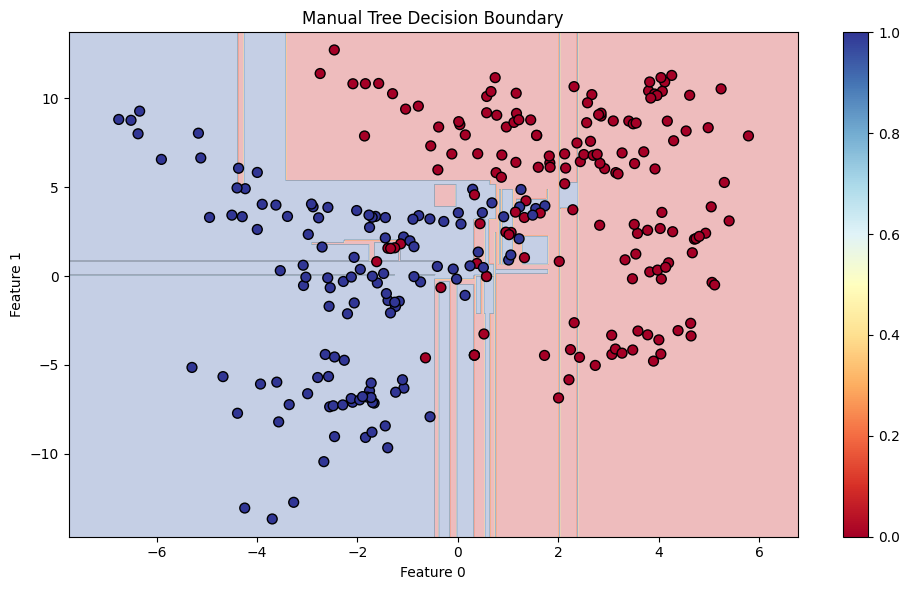

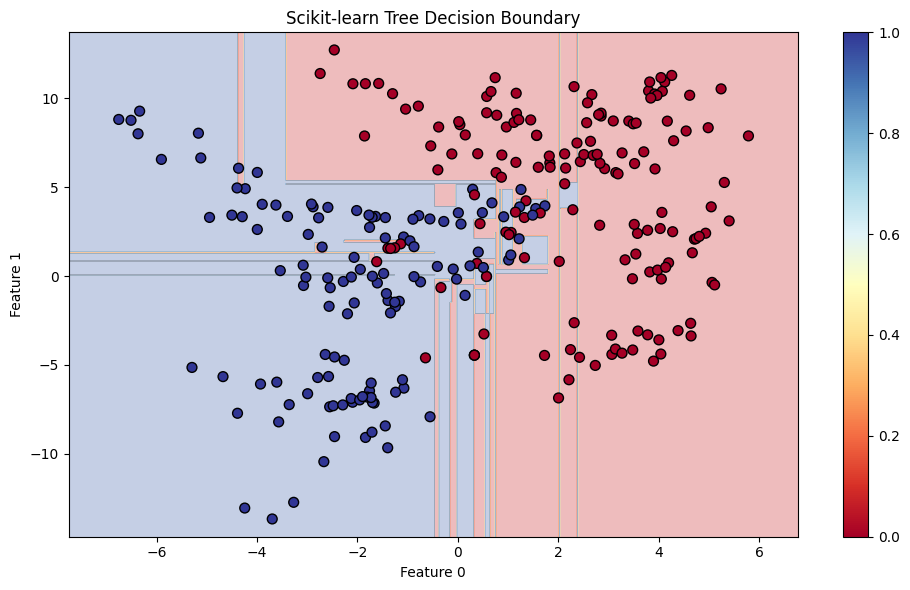


--- Part B: Linear SVM ---


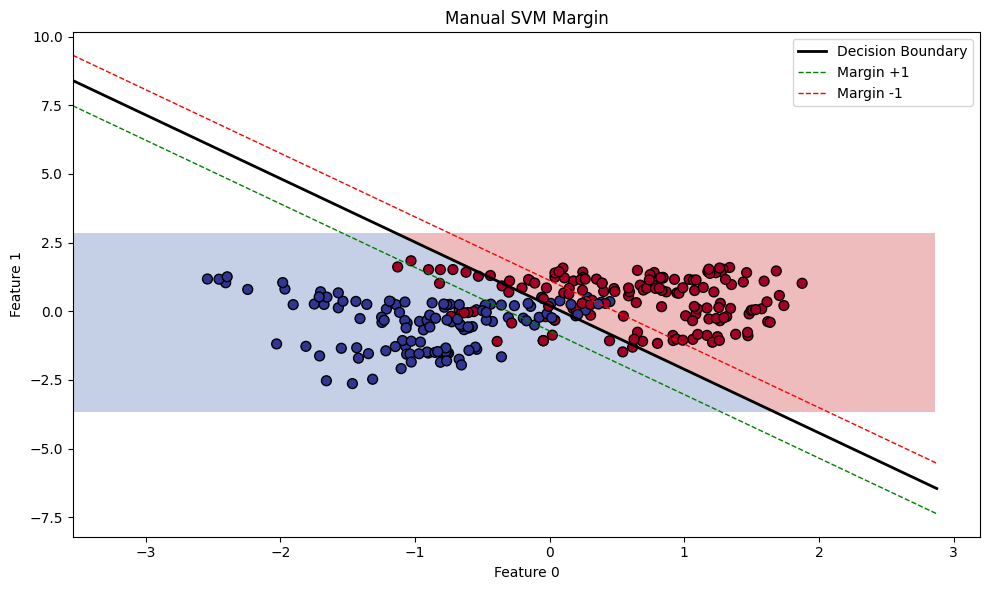


--- Part C: Kernel SVM ---


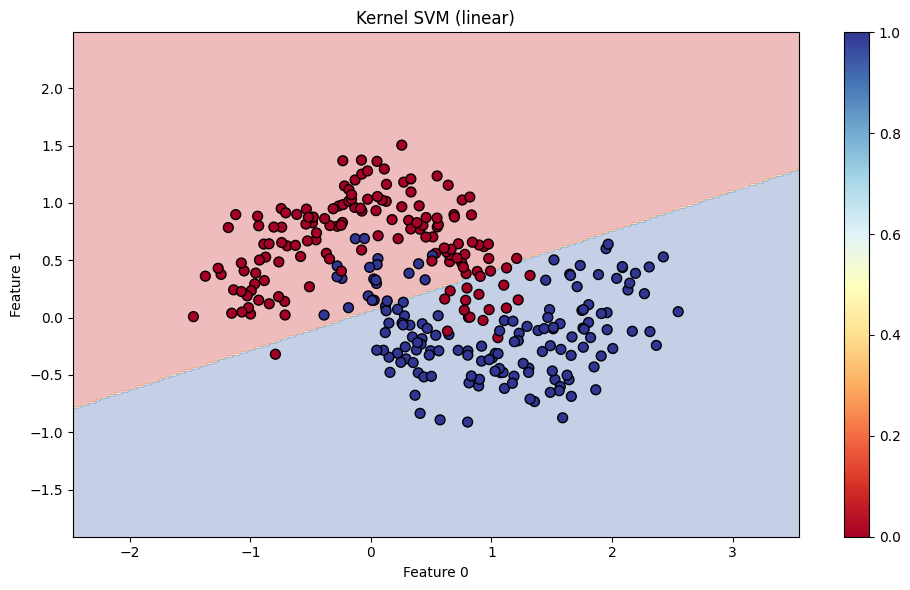

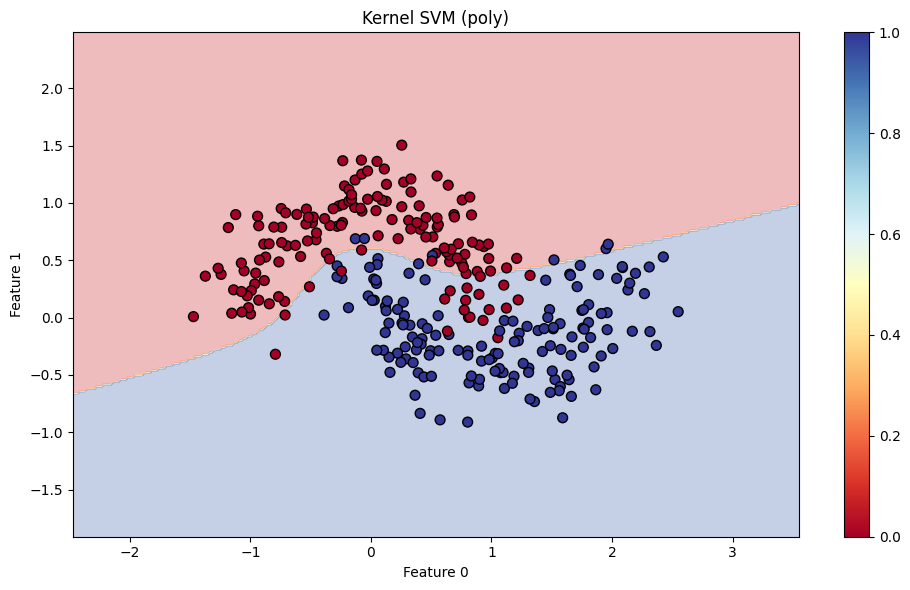

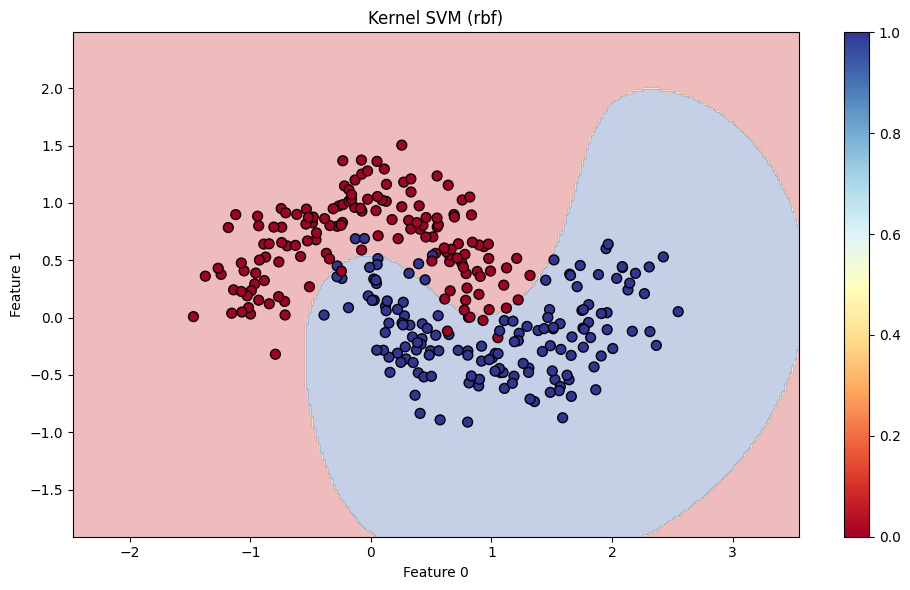


--- Part D: Final Comparison ---

Model                     Accuracy   Precision  Recall     F1         Train Time   Pred Time   
------------------------------------------------------------------------------------------
Manual Tree (4D)          0.9927     0.9839     1.0000     0.9919     1.0824       0.0005      
Sklearn Tree (4D)         0.9927     0.9839     1.0000     0.9919     0.0047       0.0003      
Manual SVM (4D)           0.9745     0.9457     1.0000     0.9721     0.0302       0.0001      
Sklearn SVM (4D)          0.9745     0.9457     1.0000     0.9721     0.0135       0.0008      
Sklearn RBF SVM (4D)      1.0000     1.0000     1.0000     1.0000     0.0058       0.0016      

Done. Plots saved as PNG files.


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.datasets import make_moons
import os
import zipfile

# ----------------------------------------------------------------------
# 1. Load Data
# ----------------------------------------------------------------------
def load_data(path="banknote_authentication.csv", zip_path="/content/banknote+authentication.zip"):
    """Load the UCI Banknote Authentication dataset, extracting it if necessary."""
    if not os.path.exists(path) and os.path.exists(zip_path):
        print(f"Extracting {zip_path}...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(".")
            # If extracted file has a slightly different name, find it
            extracted_files = zip_ref.namelist()
            for f in extracted_files:
                if f.endswith('.txt') or f.endswith('.csv'):
                    path = f
                    break

    # The dataset has 4 features and 1 target column, no header.
    data = np.loadtxt(path, delimiter=",")
    X = data[:, :-1]
    y = data[:, -1].astype(int)
    return X, y

# ----------------------------------------------------------------------
# 2. Decision Tree from Scratch
# ----------------------------------------------------------------------
class DecisionTreeScratch:
    def __init__(self, criterion="gini", max_depth=None, min_samples_split=2):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.tree = None

    def _gini(self, y):
        if len(y) == 0:
            return 0
        p = np.mean(y == 1)
        return 1 - (p ** 2) - ((1 - p) ** 2)

    def _entropy(self, y):
        if len(y) == 0:
            return 0
        p = np.mean(y == 1)
        if p == 0 or p == 1:
            return 0
        return -(p * np.log2(p)) - ((1 - p) * np.log2(1 - p))

    def _impurity(self, y):
        if self.criterion == "gini":
            return self._gini(y)
        else:
            return self._entropy(y)

    def _best_split(self, X, y):
        best_gain = -1
        best_feature = None
        best_threshold = None
        n_samples, n_features = X.shape

        for feature in range(n_features):
            # Sort by feature values and consider unique thresholds
            sorted_indices = np.argsort(X[:, feature])
            sorted_X = X[sorted_indices, feature]
            sorted_y = y[sorted_indices]

            # Thresholds are midpoints between consecutive unique values
            for i in range(1, n_samples):
                if sorted_X[i] == sorted_X[i - 1]:
                    continue
                threshold = (sorted_X[i] + sorted_X[i - 1]) / 2

                # Split
                left_mask = sorted_X <= threshold
                right_mask = ~left_mask

                if np.sum(left_mask) == 0 or np.sum(right_mask) == 0:
                    continue

                y_left = sorted_y[left_mask]
                y_right = sorted_y[right_mask]

                # Weighted impurity after split
                weight_left = len(y_left) / n_samples
                weight_right = len(y_right) / n_samples
                impurity_after = weight_left * self._impurity(y_left) + weight_right * self._impurity(y_right)

                # Impurity before split
                impurity_before = self._impurity(y)

                # Information gain
                gain = impurity_before - impurity_after

                if gain > best_gain:
                    best_gain = gain
                    best_feature = feature
                    best_threshold = threshold

        return best_feature, best_threshold, best_gain

    def _build_tree(self, X, y, depth=0):
        n_samples, n_features = X.shape
        node = {}

        # Stopping conditions
        if (self.max_depth is not None and depth >= self.max_depth) or \
           n_samples < self.min_samples_split or \
           np.all(y == y[0]):
            # Leaf node
            node["leaf"] = True
            node["prediction"] = int(np.mean(y))
            node["value"] = np.bincount(y, minlength=2)
            return node

        # Find best split
        feature, threshold, gain = self._best_split(X, y)

        if feature is None or gain <= 0:
            # No good split found, make a leaf
            node["leaf"] = True
            node["prediction"] = int(np.mean(y))
            node["value"] = np.bincount(y, minlength=2)
            return node

        # Split data
        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        node["leaf"] = False
        node["feature"] = feature
        node["threshold"] = threshold
        node["gain"] = gain
        node["left"] = self._build_tree(X[left_mask], y[left_mask], depth + 1)
        node["right"] = self._build_tree(X[right_mask], y[right_mask], depth + 1)

        return node

    def fit(self, X, y):
        self.tree = self._build_tree(X, y)
        return self

    def predict(self, X):
        predictions = []
        for x in X:
            predictions.append(self._predict_single(x, self.tree))
        return np.array(predictions)

    def _predict_single(self, x, node):
        if node["leaf"]:
            return node["prediction"]
        if x[node["feature"]] <= node["threshold"]:
            return self._predict_single(x, node["left"])
        else:
            return self._predict_single(x, node["right"])

    def get_depth(self, node=None):
        if node is None:
            node = self.tree
        if node["leaf"]:
            return 0
        return 1 + max(self.get_depth(node["left"]), self.get_depth(node["right"]))

    def print_tree(self, node=None, indent=""):
        if node is None:
            node = self.tree
        if node["leaf"]:
            print(f"{indent}Leaf: Class {node['prediction']} (Count: {node['value']})")
        else:
            print(f"{indent}Feature {node['feature']} <= {node['threshold']:.4f} (Gain: {node['gain']:.4f})")
            print(f"{indent}  Left:")
            self.print_tree(node["left"], indent + "    ")
            print(f"{indent}  Right:")
            self.print_tree(node["right"], indent + "    ")

# ----------------------------------------------------------------------
# 3. Linear SVM from Scratch
# ----------------------------------------------------------------------
class LinearSVMScratch:
    def __init__(self, C=1.0, learning_rate=0.01, n_iterations=1000):
        self.C = C
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.w = None
        self.b = None

    def fit(self, X, y):
        # Map labels to -1 and +1
        y_mapped = np.where(y == 1, 1, -1)
        n_samples, n_features = X.shape

        # Initialize weights and bias
        self.w = np.zeros(n_features)
        self.b = 0

        for _ in range(self.n_iterations):
            # Compute margins
            margins = y_mapped * (X.dot(self.w) + self.b)

            # Gradient of loss function
            # Loss = 0.5 * ||w||^2 + C * sum(max(0, 1 - margin))
            error_indices = np.where(margins < 1)[0]
            if len(error_indices) > 0:
                dw = self.w - self.C * (X[error_indices].T.dot(y_mapped[error_indices]))
                db = -self.C * y_mapped[error_indices].sum()
            else:
                dw = self.w
                db = 0

            # Update weights and bias
            self.w -= self.lr * dw
            self.b -= self.lr * db

        return self

    def predict(self, X):
        scores = X.dot(self.w) + self.b
        return np.where(scores >= 0, 1, 0)

    def get_margin(self, X):
        scores = X.dot(self.w) + self.b
        return scores

# ----------------------------------------------------------------------
# 4. Plotting Utilities
# ----------------------------------------------------------------------
def plot_decision_boundary(X, y, model, title, feature_indices=(0, 1)):
    """Plot decision boundary for a 2D model."""
    x_min, x_max = X[:, feature_indices[0]].min() - 1, X[:, feature_indices[0]].max() + 1
    y_min, y_max = X[:, feature_indices[1]].min() - 1, X[:, feature_indices[1]].max() + 1

    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))

    # Create grid points for prediction
    grid_points = np.c_[xx.ravel(), yy.ravel()]

    # Predictions
    if hasattr(model, 'predict'):
        Z = model.predict(grid_points)
    else:
        Z = np.zeros_like(grid_points[:, 0])

    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(10, 6))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.RdYlBu)
    plt.scatter(X[:, feature_indices[0]], X[:, feature_indices[1]], c=y, cmap=plt.cm.RdYlBu, edgecolors='k', s=50)
    plt.title(title)
    plt.xlabel(f"Feature {feature_indices[0]}")
    plt.ylabel(f"Feature {feature_indices[1]}")
    plt.colorbar()
    plt.tight_layout()
    plt.savefig(f"decision_boundary_{title.replace(' ', '_')}.png", dpi=150)
    plt.show()

def plot_svm_margin(X, y, model, title, feature_indices=(0, 1)):
    """Plot SVM decision boundary with margins."""
    x_min, x_max = X[:, feature_indices[0]].min() - 1, X[:, feature_indices[0]].max() + 1
    y_min, y_max = X[:, feature_indices[1]].min() - 1, X[:, feature_indices[1]].max() + 1

    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))

    grid_points = np.c_[xx.ravel(), yy.ravel()]
    scores = model.get_margin(grid_points)
    Z = np.where(scores >= 0, 1, 0).reshape(xx.shape)

    plt.figure(figsize=(10, 6))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.RdYlBu)

    # Plot margin lines
    # If the model has only 2 weights, use them directly. Otherwise, slice them.
    if len(model.w) <= 2:
        w = model.w
    else:
        w = model.w[list(feature_indices)]

    b = model.b
    if w[1] != 0:
        x_line = np.linspace(x_min, x_max, 100)
        y_line = -(w[0] * x_line + b) / w[1]
        plt.plot(x_line, y_line, 'k-', linewidth=2, label='Decision Boundary')

        y_line_plus = -(w[0] * x_line + b - 1) / w[1]
        y_line_minus = -(w[0] * x_line + b + 1) / w[1]
        plt.plot(x_line, y_line_plus, 'g--', linewidth=1, label='Margin +1')
        plt.plot(x_line, y_line_minus, 'r--', linewidth=1, label='Margin -1')

    plt.scatter(X[:, feature_indices[0]], X[:, feature_indices[1]], c=y, cmap=plt.cm.RdYlBu, edgecolors='k', s=50)
    plt.title(title)
    plt.xlabel(f"Feature {feature_indices[0]}")
    plt.ylabel(f"Feature {feature_indices[1]}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"svm_margin_{title.replace(' ', '_')}.png", dpi=150)
    plt.show()

# ----------------------------------------------------------------------
# 5. Main Execution
# ----------------------------------------------------------------------
def main():
    # Load data
    X, y = load_data()
    print(f"Dataset shape: {X.shape}")
    print(f"Class distribution: {np.bincount(y)}")

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    # Use two features for 2D plots
    feature_indices = (0, 1)
    X_train_2d = X_train[:, feature_indices]
    X_test_2d = X_test[:, feature_indices]

    # ------------------------------------------------------------------
    # Part A: Decision Tree
    # ------------------------------------------------------------------
    print("\n--- Part A: Decision Tree ---")

    # Train a 4D Decision Tree for metrics
    manual_tree = DecisionTreeScratch(criterion="gini", max_depth=None)
    manual_tree.fit(X_train, y_train)
    y_pred_manual_tree = manual_tree.predict(X_test)
    print(f"Manual Tree (4D, Gini) - Accuracy: {accuracy_score(y_test, y_pred_manual_tree):.4f}")

    # Train 2D Decision Trees specifically for 2D visualization
    manual_tree_2d = DecisionTreeScratch(criterion="gini", max_depth=None)
    manual_tree_2d.fit(X_train_2d, y_train)

    sklearn_tree_2d = DecisionTreeClassifier(criterion="gini", random_state=42)
    sklearn_tree_2d.fit(X_train_2d, y_train)

    # Plot decision boundaries with the 2D models
    plot_decision_boundary(X_test_2d, y_test, manual_tree_2d, "Manual Tree Decision Boundary")
    plot_decision_boundary(X_test_2d, y_test, sklearn_tree_2d, "Scikit-learn Tree Decision Boundary")

    # ------------------------------------------------------------------
    # Part B: Linear SVM
    # ------------------------------------------------------------------
    print("\n--- Part B: Linear SVM ---")

    # Scale features
    X_train_mean = X_train.mean(axis=0)
    X_train_std = X_train.std(axis=0)
    X_train_scaled = (X_train - X_train_mean) / X_train_std
    X_test_scaled = (X_test - X_train_mean) / X_train_std

    X_train_2d_scaled = X_train_scaled[:, feature_indices]
    X_test_2d_scaled = X_test_scaled[:, feature_indices]

    # Manual Linear SVM (2D)
    manual_svm = LinearSVMScratch(C=1.0, learning_rate=0.01, n_iterations=1000)
    manual_svm.fit(X_train_2d_scaled, y_train)
    plot_svm_margin(X_test_2d_scaled, y_test, manual_svm, "Manual SVM Margin")

    # ------------------------------------------------------------------
    # Part C: Kernel SVM
    # ------------------------------------------------------------------
    print("\n--- Part C: Kernel SVM ---")
    X_moons, y_moons = make_moons(n_samples=300, noise=0.2, random_state=42)
    kernels = ['linear', 'poly', 'rbf']
    for kernel in kernels:
        svm = SVC(kernel=kernel, random_state=42)
        svm.fit(X_moons, y_moons)
        plot_decision_boundary(X_moons, y_moons, svm, f"Kernel SVM ({kernel})")

    # ------------------------------------------------------------------
    # Part D: Final Comparison
    # ------------------------------------------------------------------
    print("\n--- Part D: Final Comparison ---")
    results = {}

    # Manual Decision Tree (4D)
    start_time = time.time()
    manual_tree_4d = DecisionTreeScratch(criterion="gini", max_depth=None)
    manual_tree_4d.fit(X_train, y_train)
    train_time = time.time() - start_time
    start_time = time.time()
    y_pred = manual_tree_4d.predict(X_test)
    pred_time = time.time() - start_time
    results['Manual Tree (4D)'] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'train_time': train_time,
        'pred_time': pred_time
    }

    # Sklearn Decision Tree (4D)
    start_time = time.time()
    sklearn_tree_4d = DecisionTreeClassifier(criterion="gini", random_state=42)
    sklearn_tree_4d.fit(X_train, y_train)
    train_time = time.time() - start_time
    start_time = time.time()
    y_pred = sklearn_tree_4d.predict(X_test)
    pred_time = time.time() - start_time
    results['Sklearn Tree (4D)'] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'train_time': train_time,
        'pred_time': pred_time
    }

    # Manual Linear SVM (4D)
    start_time = time.time()
    manual_svm_4d = LinearSVMScratch(C=1.0, learning_rate=0.01, n_iterations=1000)
    manual_svm_4d.fit(X_train_scaled, y_train)
    train_time = time.time() - start_time
    start_time = time.time()
    y_pred = manual_svm_4d.predict(X_test_scaled)
    pred_time = time.time() - start_time
    results['Manual SVM (4D)'] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'train_time': train_time,
        'pred_time': pred_time
    }

    # Sklearn Linear SVM (4D)
    start_time = time.time()
    sklearn_svm_4d = SVC(kernel='linear', C=1.0, random_state=42)
    sklearn_svm_4d.fit(X_train_scaled, y_train)
    train_time = time.time() - start_time
    start_time = time.time()
    y_pred = sklearn_svm_4d.predict(X_test_scaled)
    pred_time = time.time() - start_time
    results['Sklearn SVM (4D)'] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'train_time': train_time,
        'pred_time': pred_time
    }

    # Sklearn RBF SVM (4D)
    start_time = time.time()
    sklearn_rbf_svm = SVC(kernel='rbf', C=1.0, random_state=42)
    sklearn_rbf_svm.fit(X_train_scaled, y_train)
    train_time = time.time() - start_time
    start_time = time.time()
    y_pred = sklearn_rbf_svm.predict(X_test_scaled)
    pred_time = time.time() - start_time
    results['Sklearn RBF SVM (4D)'] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'train_time': train_time,
        'pred_time': pred_time
    }

    # Print results in a table format
    print(f"\n{'Model':<25} {'Accuracy':<10} {'Precision':<10} {'Recall':<10} {'F1':<10} {'Train Time':<12} {'Pred Time':<12}")
    print("-" * 90)
    for model_name, metrics in results.items():
        print(f"{model_name:<25} {metrics['accuracy']:<10.4f} {metrics['precision']:<10.4f} {metrics['recall']:<10.4f} {metrics['f1']:<10.4f} {metrics['train_time']:<12.4f} {metrics['pred_time']:<12.4f}")

    print("\nDone. Plots saved as PNG files.")

if __name__ == "__main__":
    main()